# PyTorch building-age comparison

Start here to learn the small residual network and compare it with the RF, raw MLP and frozen autoencoder. See [the report](../../docs/PYTORCH.md) for sources and recommendations.

Five spatial development folds, three matched repetitions, **25 Amsterdam labels/class**. These folds have been used previously for development. No independent test score is available. The raw/SSL MLP predictions already existed; the residual network was trained for this comparison.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'pyproject.toml').exists():
    if ROOT == ROOT.parent:
        raise RuntimeError('Run inside the repository')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts.compare_torch import CONFIG, ResidualMLP, verify
OUT = ROOT / 'data/torch_comparison'
verify()

Verified 75 run scores, 389,880 probability rows and artifact hashes.


## Inspect the network

Each residual block adds a learned correction to its input. LayerNorm and dropout regularize the small network. The output contains four raw logits; cross entropy converts these into the supervised learning loss. Softmax is only needed when producing probabilities.

Inspect `scripts/compare_torch.py` for the complete optimization loop. Preprocessing fits separately on each 100-location labeled sample. Outer labels never select epochs or model settings.

In [2]:
print(CONFIG)
model = ResidualMLP(54)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

{'width': 32, 'residual_blocks': 2, 'dropout': 0.2, 'epochs': 300, 'learning_rate': 0.001, 'weight_decay': 0.01, 'folds': 5, 'repetitions': 3, 'labels_per_class': 25, 'rf_blend_weight': 0.5, 'device': 'cpu'}
ResidualMLP(
  (input): Linear(in_features=54, out_features=32, bias=True)
  (blocks): ModuleList(
    (0-1): 2 x Sequential(
      (0): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (1): Linear(in_features=32, out_features=32, bias=True)
      (2): ReLU()
      (3): Dropout(p=0.2, inplace=False)
      (4): Linear(in_features=32, out_features=32, bias=True)
      (5): Dropout(p=0.2, inplace=False)
    )
  )
  (output): Sequential(
    (0): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=4, bias=True)
  )
)
Trainable parameters: 6308


## Compare matched scores

Repetitions are averaged within folds first. Fold SD describes variability and is not a confidence interval. The RF has access to Madrid labels; the standalone neural models do not.

,macro_f1,weighted_f1,accuracy,balanced_accuracy,macro_f1_fold_sd,delta_vs_rf
method,,,,,,
original_blend,0.5494,0.5636,0.5652,0.5559,0.0258,0.0000
raw_mlp,0.5447,0.5579,0.5576,0.5654,0.0254,-0.0047
residual_mlp,0.5346,0.5439,0.5434,0.5618,0.0314,-0.0148
rf_residual_blend,0.5416,0.5509,0.5503,0.5675,0.0310,-0.0078
ssl_mlp,0.5328,0.5481,0.5489,0.5538,0.0369,-0.0166


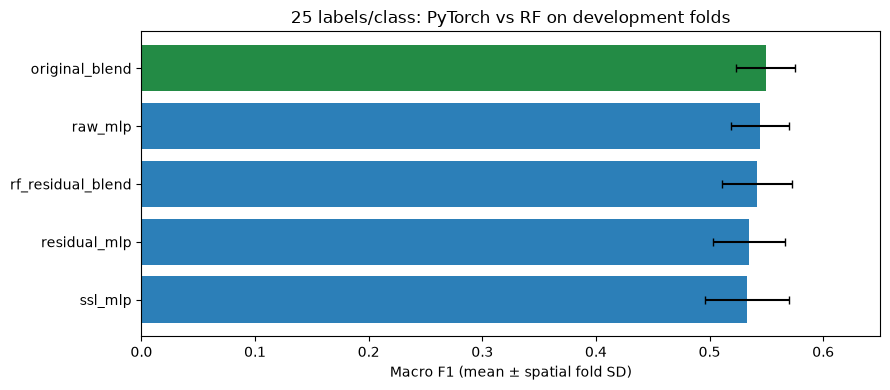

In [3]:
summary = pd.read_csv(OUT / 'summary.csv', index_col='method')
display(summary.round(4))
ordered = summary.sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ordered.index, ordered.macro_f1, xerr=ordered.macro_f1_fold_sd,
        color=['#2c7fb8' if name != 'original_blend' else '#238b45' for name in ordered.index], capsize=3)
ax.set(xlabel='Macro F1 (mean ± spatial fold SD)', xlim=(0, .65),
       title='25 labels/class: PyTorch vs RF on development folds')
fig.tight_layout()
fig.savefig(ROOT / 'docs/assets/torch_comparison.png', dpi=160)
plt.show()

In [4]:
classes = pd.read_csv(OUT / 'class_metrics.csv')
display(classes.groupby(['method', 'fold', 'age_class']).f1.mean()
        .groupby(['method', 'age_class']).mean().unstack('age_class').round(4))
display(pd.read_csv(OUT / 'paired_fold_deltas.csv').round(4))

age_class,1,2,3,4
method,,,,
original_blend,0.6337,0.5872,0.4847,0.4919
raw_mlp,0.6404,0.5302,0.5396,0.4687
residual_mlp,0.6326,0.5065,0.5210,0.4783
rf_residual_blend,0.6370,0.5169,0.5262,0.4861
ssl_mlp,0.6427,0.5214,0.5199,0.4471


,fold,original_blend,raw_mlp,residual_mlp,rf_residual_blend,ssl_mlp
0,0,0.0,0.0126,-0.0091,-0.0011,-0.0004
1,1,0.0,-0.0046,-0.0114,-0.0058,-0.0372
2,2,0.0,-0.0099,-0.0072,-0.0011,-0.0283
3,3,0.0,-0.0099,-0.0157,-0.0080,0.0091
4,4,0.0,-0.0116,-0.0307,-0.0231,-0.0263


## Training curves

A decreasing training loss shows optimization progress; it does not establish better geographic generalization. Epoch 300 was fixed before evaluation. There is no outer-fold early stopping.

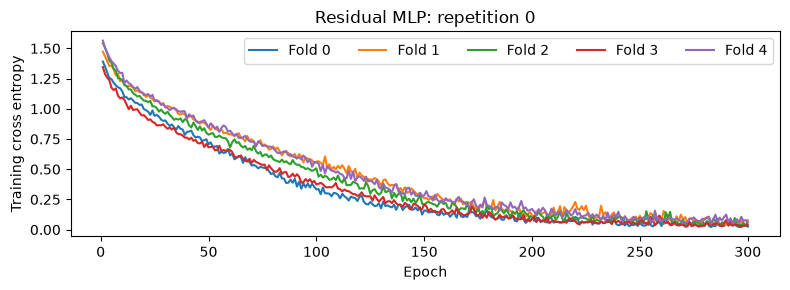

In [5]:
history = pd.read_csv(OUT / 'training_history.csv')
fig, ax = plt.subplots(figsize=(8, 3))
for fold, frame in history.loc[history.repetition.eq(0)].groupby('fold'):
    ax.plot(frame.epoch, frame.training_loss, label=f'Fold {fold}')
ax.set(xlabel='Epoch', ylabel='Training cross entropy', title='Residual MLP: repetition 0')
ax.legend(ncol=5)
fig.tight_layout()
plt.show()

## Reproduce training

From the repository root:

```bash
uv sync --locked --extra deep-learning
uv run --extra deep-learning python -m scripts.compare_torch
uv run --extra deep-learning python -m scripts.compare_torch --verify
```

This requires the existing baseline, original improvement probabilities and PyTorch SSL artifacts. Default notebook cells only verify and inspect the saved comparison.

## Conclusion

**No macro-F1 gain: retain the RF blend (0.5494).** The raw PyTorch MLP is the strongest tested neural model (0.5447). The residual MLP scores 0.5346; its fixed RF blend scores 0.5416. The frozen autoencoder scores 0.5328.

Recommended next experiments: Madrid supervised pretraining with Amsterdam fine-tuning, then TabM; FT-Transformer is a later candidate. A temporal CNN requires an ordered raw-sequence pipeline. These methods remain untested. Choose settings using inner spatial splits and evaluate the final choice on a new untouched geographic test.